In [26]:
import csv

import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split

RANDOM_SEED = 42

In [27]:
%pip install numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
%pip install tensorflow scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
%pip install pandas seaborn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# 各パス指定

In [30]:
dataset = 'model/keypoint_classifier/keypoint.csv'
model_save_path = 'model/keypoint_classifier/keypoint_classifier.keras'

# 分類数設定

In [31]:
NUM_CLASSES = 26

# 学習データ読み込み

In [32]:
X_dataset = np.loadtxt(dataset, delimiter=',', dtype='float32', usecols=list(range(1, (21 * 2) + 1)))

In [33]:
y_dataset = np.loadtxt(dataset, delimiter=',', dtype='int32', usecols=(0))

In [34]:
X_train, X_test, y_train, y_test = train_test_split(X_dataset, y_dataset, train_size=0.75, random_state=RANDOM_SEED)

# モデル構築

In [35]:
model = tf.keras.models.Sequential([
    tf.keras.layers.Input((21 * 2, )),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(20, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(10, activation='relu'),
    tf.keras.layers.Dense(NUM_CLASSES, activation='softmax')
])

In [36]:
model.summary()  # tf.keras.utils.plot_model(model, show_shapes=True)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dropout_2 (Dropout)                  │ (None, 42)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 20)                  │             860 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_3 (Dropout)                  │ (None, 20)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 10)                  │             210 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 26)                  │             286 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,356 (5.30 KB)

 Trainable params: 1,356 (5.30 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
# モデルチェックポイントのコールバック
cp_callback = tf.keras.callbacks.ModelCheckpoint(
    model_save_path, verbose=1, save_weights_only=False)
# 早期打ち切り用コールバック
es_callback = tf.keras.callbacks.EarlyStopping(patience=20, verbose=1)

In [38]:
# モデルコンパイル
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# モデル訓練

In [39]:
model.fit(
    X_train,
    y_train,
    epochs=1000,
    batch_size=128,
    validation_data=(X_test, y_test),
    callbacks=[cp_callback, es_callback]
)

Epoch 1/1000
134/139 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.1129 - loss: 3.0310
Epoch 1: saving model to model/keypoint_classifier/keypoint_classifier.keras

Epoch 1: finished saving model to model/keypoint_classifier/keypoint_classifier.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.1144 - loss: 3.0243 - val_accuracy: 0.2307 - val_loss: 2.7436
Epoch 2/1000
136/139 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2371 - loss: 2.6809
Epoch 2: saving model to model/keypoint_classifier/keypoint_classifier.keras

Epoch 2: finished saving model to model/keypoint_classifier/keypoint_classifier.keras
139/139 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.2379 - loss: 2.6781 - val_accuracy: 0.3758 - val_loss: 2.3877
Epoch 3/1000
137/139 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2938 - loss: 2.4245
Epoch 3: saving model to model/keypoint_classifier/keypoint_classifier.keras

Epoch 3: finished saving model to model/keypoint_classifier/keypoint_classifier.keras
139/139 ━━

In [40]:
# モデル評価
val_loss, val_acc = model.evaluate(X_test, y_test, batch_size=128)

47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9048 - loss: 0.4040


In [41]:
# 保存したモデルのロード
model = tf.keras.models.load_model(model_save_path)

In [42]:
# 推論テスト
predict_result = model.predict(np.array([X_test[0]]))
print(np.squeeze(predict_result))
print(np.argmax(np.squeeze(predict_result)))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
[3.0423110e-04 4.3198173e-13 6.4538026e-06 5.0714500e-13 1.0328457e-06
 6.5088844e-11 5.2858810e-05 1.8882897e-04 1.4738185e-11 1.0606799e-33
 3.0044887e-09 1.5311345e-08 1.2223335e-21 2.9970644e-04 1.8616124e-09
 2.1674258e-10 1.9074096e-21 5.0907718e-33 1.3685691e-11 0.0000000e+00
 0.0000000e+00 4.3658349e-30 3.1691797e-25 1.4200564e-17 9.9914682e-01
 0.0000000e+00]
24


# 混同行列

185/185 ━━━━━━━━━━━━━━━━━━━━ 0s 712us/step


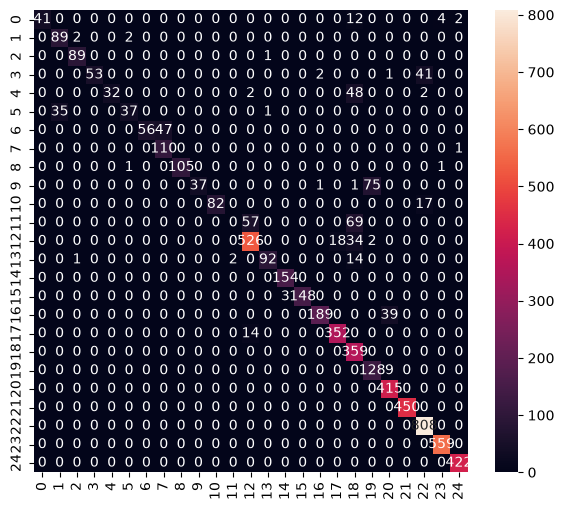

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.69      0.82        59
           1       0.72      0.96      0.82        93
           2       0.97      0.99      0.98        90
           3       1.00      0.55      0.71        97
           4       1.00      0.38      0.55        84
           5       0.93      0.51      0.65        73
           6       1.00      0.54      0.70       103
           7       0.70      0.99      0.82       111
           8       1.00      0.98      0.99       107
           9       1.00      0.32      0.49       114
          10       1.00      0.83      0.91        99
          11       0.00      0.00      0.00       126
          12       0.88      0.91      0.89       580
          13       0.98      0.84      0.91       109
          14       0.98      1.00      0.99       154
          15       1.00      0.98      0.99       151
          16       0.98      0.83      0.90       228
     

In [43]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

def print_confusion_matrix(y_true, y_pred, report=True):
    labels = sorted(list(set(y_true)))
    cmx_data = confusion_matrix(y_true, y_pred, labels=labels)
    
    df_cmx = pd.DataFrame(cmx_data, index=labels, columns=labels)
 
    fig, ax = plt.subplots(figsize=(7, 6))
    sns.heatmap(df_cmx, annot=True, fmt='g' ,square=False)
    ax.set_ylim(len(set(y_true)), 0)
    plt.show()
    
    if report:
        print('Classification Report')
        print(classification_report(y_test, y_pred))

Y_pred = model.predict(X_test)
y_pred = np.argmax(Y_pred, axis=1)

print_confusion_matrix(y_test, y_pred)

# Tensorflow-Lite用のモデルへ変換

In [44]:
# 推論専用のモデルとして保存
model.save(model_save_path, include_optimizer=False)

In [45]:
# モデルを変換(量子化)
tflite_save_path = 'model/keypoint_classifier/keypoint_classifier.tflite'

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_quantized_model = converter.convert()

open(tflite_save_path, 'wb').write(tflite_quantized_model)

INFO:tensorflow:Assets written to: C:\Users\tuana\AppData\Local\Temp\tmpxyotcsyl\assets


INFO:tensorflow:Assets written to: C:\Users\tuana\AppData\Local\Temp\tmpxyotcsyl\assets


Saved artifact at 'C:\Users\tuana\AppData\Local\Temp\tmpxyotcsyl'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 42), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 26), dtype=tf.float32, name=None)
Captures:
  2241320084176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2241320078992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2241320078608: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2241320085520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2241320087440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2241320079184: TensorSpec(shape=(), dtype=tf.resource, name=None)


7656

# 推論テスト

In [46]:
interpreter = tf.lite.Interpreter(model_path=tflite_save_path)
interpreter.allocate_tensors()

C:\Users\tuana\AppData\Local\Programs\Python\Python311\Lib\site-packages\tensorflow\lite\python\interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [47]:
# 入出力テンソルを取得
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

In [48]:
interpreter.set_tensor(input_details[0]['index'], np.array([X_test[0]]))

In [49]:
%%time
# 推論実施
interpreter.invoke()
tflite_results = interpreter.get_tensor(output_details[0]['index'])

CPU times: total: 15.6 ms
Wall time: 1 ms


In [50]:
print(np.squeeze(tflite_results))
print(np.argmax(np.squeeze(tflite_results)))

[3.0423107e-04 4.3198003e-13 6.4538149e-06 5.0714402e-13 1.0328467e-06
 6.5088594e-11 5.2858912e-05 1.8882878e-04 1.4738155e-11 1.0606877e-33
 3.0044713e-09 1.5311345e-08 1.2223334e-21 2.9970615e-04 1.8615947e-09
 2.1674092e-10 1.9074094e-21 5.0907711e-33 1.3685690e-11 0.0000000e+00
 0.0000000e+00 4.3657676e-30 3.1691912e-25 1.4200562e-17 9.9914682e-01
 0.0000000e+00]
24
